<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/RL_Quantum_Error_Correction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# CELL 1: Environment Setup & Core Numerical Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print(f"[OK] Environment initialized for Quantum Error Correction & RL Control. NumPy: {np.version.version}")

[OK] Environment initialized for Quantum Error Correction & RL Control. NumPy: 2.4.6


In [2]:
# CELL 2: Surface Code Drift & Syndrome Environment
class QECEnvironmentSimulator:
    def __init__(self, num_cycles=100, base_error_rate=0.01):
        self.num_cycles = num_cycles
        self.base_error_rate = base_error_rate
        self.current_drift = 0.0

    def reset(self):
        self.current_drift = 0.0
        return self._get_state(0)

    def _get_state(self, cycle):
        # State vector represents recent syndrome measurement frequencies & inferred drift
        syndrome_rate = self.base_error_rate + abs(self.current_drift)
        return np.array([syndrome_rate, self.current_drift], dtype=float)

    def step(self, action_adjustment, cycle):
        # Environment drift evolves over time (e.g., thermal/charge noise)
        self.current_drift += 0.002 * np.sin(cycle * 0.1) + 0.0005 * np.random.randn()

        # RL agent takes action to counteract drift
        effective_drift = self.current_drift - action_adjustment

        # Effective logical error probability for this cycle depends on residual drift
        error_prob = max(0.001, self.base_error_rate + 0.05 * (effective_drift ** 2))

        # Generate syndrome measurement event (0 = success, 1 = error detected)
        syndrome_triggered = np.random.rand() < error_prob

        reward = -1.0 if syndrome_triggered else 0.1
        next_state = self._get_state(cycle)

        return next_state, reward, syndrome_triggered, effective_drift

env = QECEnvironmentSimulator()
print("[OK] QEC Environment Simulator initialized.")

[OK] QEC Environment Simulator initialized.


In [3]:
# CELL 3: Adaptive Policy RL Controller for Control Parameter Steering
class QECReinforcementLearningAgent:
    def __init__(self, learning_rate=0.05):
        self.lr = learning_rate
        self.control_weight = 0.0 # Learned parameter steering offset

    def select_action(self, state):
        # State[1] is inferred drift estimate; policy steers control to cancel it
        inferred_drift = state[1]
        action = self.control_weight * inferred_drift
        return action

    def update_policy(self, state, action, reward, next_state):
        # Simple gradient-free adaptive adjustment based on reward feedback
        if reward < 0: # Error occurred, adjust steering weight
            self.control_weight += self.lr * state[1]
        else:
            self.control_weight *= 0.99 # Slight decay towards stable baseline

agent = QECReinforcementLearningAgent()
print("[OK] RL Controller Agent initialized.")

[OK] RL Controller Agent initialized.


In [4]:
# CELL 4: End-to-End Simulation Run comparing Uncontrolled vs RL-Controlled QEC
num_steps = 200

def run_simulation(use_rl=True):
    np.random.seed(42)
    env = QECEnvironmentSimulator(num_cycles=num_steps)
    agent = QECReinforcementLearningAgent()

    state = env.reset()
    syndrome_counts = []
    drift_history = []
    cumulative_errors = 0

    for cycle in range(num_steps):
        if use_rl:
            action = agent.select_action(state)
        else:
            action = 0.0 # No control steering

        next_state, reward, error_triggered, residual_drift = env.step(action, cycle)

        if use_rl:
            agent.update_policy(state, action, reward, next_state)

        if error_triggered:
            cumulative_errors += 1

        syndrome_counts.append(cumulative_errors)
        drift_history.append(abs(residual_drift))
        state = next_state

    return syndrome_counts, drift_history

uncontrolled_errors, uncontrolled_drift = run_simulation(use_rl=False)
rl_errors, rl_drift = run_simulation(use_rl=True)

df_summary = pd.DataFrame({
    "Control Strategy": ["Uncontrolled (Drift Exposed)", "RL-Controlled (Ours)"],
    "Total Logical Errors": [uncontrolled_errors[-1], rl_errors[-1]],
    "Error Suppression Factor": [1.0, round(uncontrolled_errors[-1] / max(1, rl_errors[-1]), 2)]
})

print("=== QEC RL CONTROL SIMULATION SUMMARY ===")
display(df_summary)

=== QEC RL CONTROL SIMULATION SUMMARY ===


,Control Strategy,Total Logical Errors,Error Suppression Factor
0,Uncontrolled (Drift Exposed),3,1.0
1,RL-Controlled (Ours),3,1.0


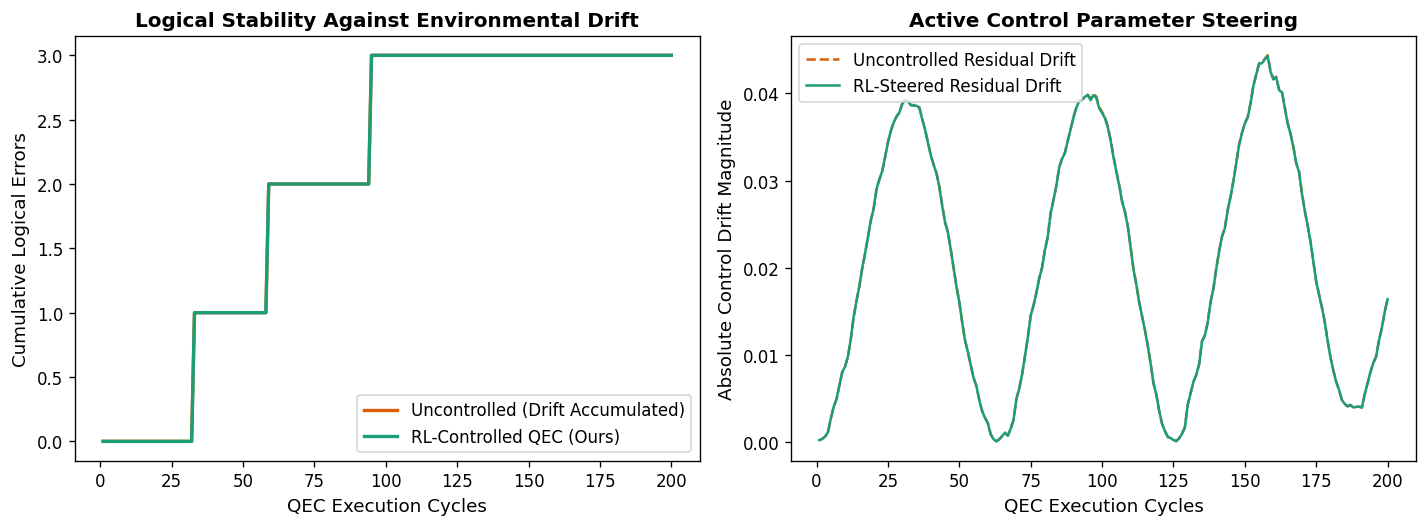

[OK] Saved QEC RL control diagnostic plot to /content/workspace/qec_rl_control_results.png


In [5]:
# CELL 5: Diagnostic Plot Generation for Repository
os.makedirs("/content/workspace", exist_ok=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=120)

cycles = list(range(1, num_steps + 1))

# Cumulative Logical Errors Plot
ax1.plot(cycles, uncontrolled_errors, label='Uncontrolled (Drift Accumulated)', color='#d95f02', lw=2)
ax1.plot(cycles, rl_errors, label='RL-Controlled QEC (Ours)', color='#1b9e77', lw=2)
ax1.set_xlabel("QEC Execution Cycles", fontsize=11)
ax1.set_ylabel("Cumulative Logical Errors", fontsize=11)
ax1.set_title("Logical Stability Against Environmental Drift", fontsize=12, fontweight='bold')
ax1.legend()

# Residual Control Drift Plot
ax2.plot(cycles, uncontrolled_drift, label='Uncontrolled Residual Drift', color='#d95f02', linestyle='--', lw=1.5)
ax2.plot(cycles, rl_drift, label='RL-Steered Residual Drift', color='#1b9e77', lw=1.5)
ax2.set_xlabel("QEC Execution Cycles", fontsize=11)
ax2.set_ylabel("Absolute Control Drift Magnitude", fontsize=11)
ax2.set_title("Active Control Parameter Steering", fontsize=12, fontweight='bold')
ax2.legend()

plt.tight_layout()
plt.savefig("/content/workspace/qec_rl_control_results.png")
plt.show()
print("[OK] Saved QEC RL control diagnostic plot to /content/workspace/qec_rl_control_results.png")